# Clasificación: XGBoost

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from Modelado import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_CLF, ESTRATEGIAS, N_ITER_FASE1,
    cargar_split, separar_x_y, crear_cv, dispositivo_modelo, verificar_smotenc,
    describir_espacio, ejecutar_fase1, formatear_tabla_cv, graficar_estrategias, elegir_mejor, guardar_fase1,
    formatear_hiperparametros, tabla_hiperparametros,
)

CLAVE = "xgboost"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_modelo(CLAVE),
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,XGBoost
USAR_GPU,True
GPU detectada por librería,"xgboost: cuda, catboost: GPU, lightgbm: cuda"
Dispositivo de entrenamiento,GPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y(df_train)
cv = crear_cv(SEED)

pd.DataFrame({
    "Filas": [len(X_train)],
    "Predictores": [X_train.shape[1]],
    "Deprimidos": [int(y_train.sum())],
    "Prevalencia": [round(y_train.mean(), 3)],
}, index=pd.Index(["Train"], name="Conjunto"))

,Filas,Predictores,Deprimidos,Prevalencia
Conjunto,,,,
Train,3848,6,630,0.164


### Estrategias de Manejo del Desbalance

| Estrategia | Qué hace | En XGBoost |
|---|---|---|
| **a) Nativo** | Sin balanceo: el modelo ve la proporción real (16% de positivos). | — |
| **b) Pesos de clase** | Los errores en la clase minoritaria pesan más al entrenar. | `scale_pos_weight = n_neg / n_pos` del train (≈ 5.1) |
| **c) SMOTENC** | Genera deprimidos sintéticos a partir de sus vecinos deprimidos más cercanos, hasta igualar las clases. Sin pesos de clase. | `SMOTENC(categorical_features=["sex"], random_state=42)` |

In [4]:
tabla_clases, tabla_sexo = verificar_smotenc(X_train, y_train, seed=SEED)
display(tabla_clases)
display(tabla_sexo)

✓ sex solo toma los valores ['Boy', 'Girl']
✓ Clases balanceadas: {0: 3218, 1: 3218}


,Antes,Después,Sintéticos
Deprimido,,,
0,3218,3218,0
1,630,3218,2588


Deprimido,0,1
Sexo,,
Boy,1789,770
Girl,1429,2448


### Espacio de Búsqueda

Se exploraron 25 combinaciones aleatorias por estrategia. Se variaron la complejidad del modelo (profundidad de 2 a 6, entre 100 y 600 árboles, `min_child_weight` de 1 a 10), la regularización por muestreo de filas y columnas (0.6 a 1) y la tasa de aprendizaje en escala logarítmica (0.01 a 0.2).

In [5]:
describir_espacio(CLAVE).style.set_caption(f"Combinaciones por estrategia: {N_ITER_FASE1[CLAVE]}")

,Valores
Hiperparámetro,
n_estimators,entero entre 100 y 600
max_depth,entero entre 2 y 6
learning_rate,log-uniforme entre 0.01 y 0.2
subsample,uniforme entre 0.6 y 1
colsample_bytree,uniforme entre 0.6 y 1
min_child_weight,entero entre 1 y 10


### Validación Cruzada por Estrategia

Para cada estrategia se ejecuta un `RandomizedSearchCV` **solo sobre el train**, con los mismos folds y `scoring` PR-AUC (`average_precision`).

In [6]:
tabla, pipelines, hiperparametros = ejecutar_fase1(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo (sin balanceo)  PR-AUC = 0.3915 ± 0.0506  (32 s)
✓ Pesos de clase         PR-AUC = 0.3910 ± 0.0476  (33 s)
✓ SMOTENC                PR-AUC = 0.3913 ± 0.0494  (39 s)


In [7]:
vista = formatear_tabla_cv(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=ESTRATEGIAS)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Tiempo (s)
Estrategia,,,,,,,
Nativo (sin balanceo),0.391 ± 0.051,0.749 ± 0.031,0.552 ± 0.103,0.046 ± 0.024,0.083 ± 0.040,0.837 ± 0.002,32.0
Pesos de clase,0.391 ± 0.048,0.749 ± 0.030,0.302 ± 0.023,0.660 ± 0.062,0.414 ± 0.034,0.695 ± 0.015,33.0
SMOTENC,0.391 ± 0.049,0.747 ± 0.028,0.334 ± 0.040,0.568 ± 0.045,0.421 ± 0.044,0.742 ± 0.026,39.0


Las tres estrategias obtienen la misma PR-AUC (0.391, con desviaciones de 0.048 a 0.051 que se solapan por completo) y prácticamente la misma ROC-AUC (0.749 ± 0.031, 0.749 ± 0.030 y 0.747 ± 0.028). La capacidad discriminativa existe, pero es modesta.

Las diferencias aparecen en las demás métricas, calculadas con el umbral de 0.5. El nativo tiene la precision más alta (0.552), pero también la más inestable (± 0.103), porque predice tan pocos positivos que cada acierto o error mueve mucho la métrica en cada fold. Su recall de 0.046 ± 0.024 implica que se le escapa más del 95% de los casos, lo que deja el F1 en 0.083 ± 0.040. Su accuracy de 0.837 ± 0.002 es la más alta y la más estable, pero coincide con la de predecir siempre “no deprimido” (1 − 0.164 = 0.836), así que no refleja capacidad predictiva.

El modelo con pesos de clase alcanza un recall de 0.660 ± 0.062 con una precision de 0.302 ± 0.023, y SMOTENC un recall de 0.568 ± 0.045 con una precision de 0.334 ± 0.040. Ambos llegan a un F1 equivalente (0.414 ± 0.034 y 0.421 ± 0.044), y su accuracy baja a 0.695 ± 0.015 y 0.742 ± 0.026 por el aumento de falsos positivos en la clase mayoritaria.

In [8]:
# Mejores hiperparámetros por estrategia
tabla_hiperparametros(hiperparametros)

,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,subsample
Estrategia,,,,,,
Nativo (sin balanceo),0.6102,0.01382,2,4,195,0.8782
Pesos de clase,0.6102,0.01382,2,4,195,0.8782
SMOTENC,0.7434,0.01415,2,8,367,0.7324


El nativo y el de pesos de clase eligieron exactamente la misma configuración. Las tres estrategias favorecen árboles muy poco profundos (`max_depth=2`) y tasas de aprendizaje bajas (alrededor de 0.014), lo que sugiere una señal simple, dominada por efectos principales. SMOTENC requirió más árboles (367) y un `min_child_weight` mayor (8), probablemente para compensar el ruido de los casos sintéticos.

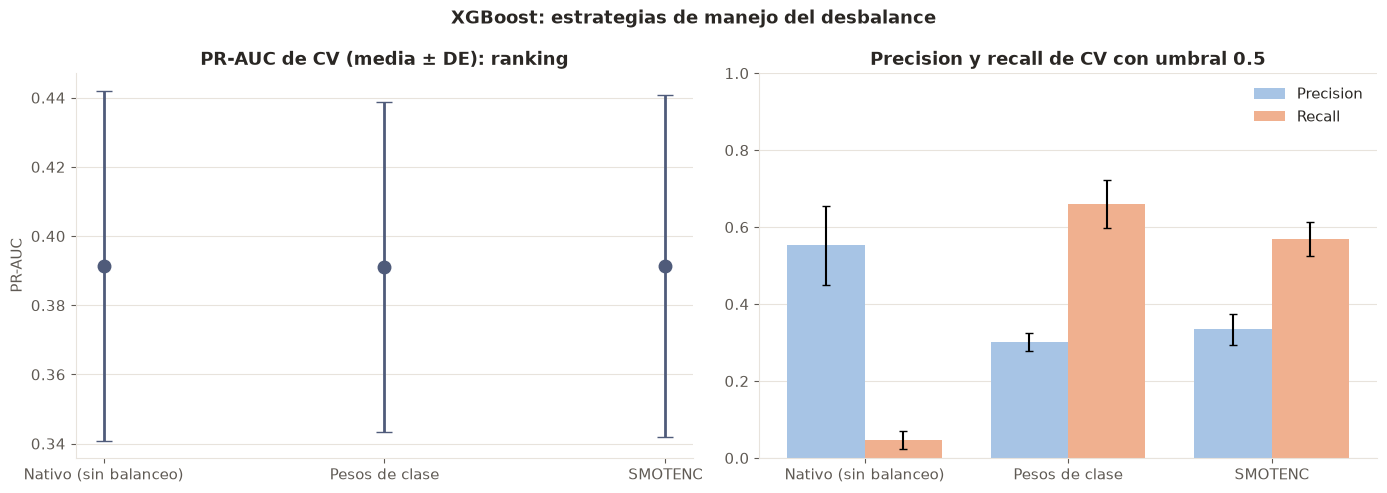

In [9]:
fig = graficar_estrategias(tabla, NOMBRES_CLF[CLAVE])
plt.show()

La gráfica confirma que las tres estrategias producen esencialmente el mismo modelo. La PR-AUC media es prácticamente idéntica (~0.39) y las barras de desviación se solapan casi por completo, así que ni los pesos de clase ni SMOTENC mejoran la capacidad del XGBoost para ordenar los positivos por encima de los negativos. Lo que sí cambia es el comportamiento con el umbral fijo de 0.5. El modelo nativo casi nunca predice la clase minoritaria, por lo que tiene una precision aceptable (~0.55) pero un recall muy bajo (~0.05). Los pesos de clase y SMOTENC inflan las probabilidades de los positivos y desplazan el punto de operación hacia más recall (~0.66 y ~0.57) a costa de menos precision (~0.30 y ~0.33).

### Selección del Mejor Modelo XGBoost

Se elige la estrategia con **mayor PR-AUC media de CV**.

In [10]:
estrategia_ganadora, explicacion = elegir_mejor(tabla)

pd.Series({
    "Estrategia ganadora": ESTRATEGIAS[estrategia_ganadora],
    "PR-AUC de CV": f"{tabla.loc[estrategia_ganadora, 'PR-AUC media']:.4f} ± {tabla.loc[estrategia_ganadora, 'PR-AUC DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[estrategia_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,XGBoost
Estrategia ganadora,Nativo (sin balanceo)
PR-AUC de CV,0.3915 ± 0.0506
Hiperparámetros,"colsample_bytree=0.6102, learning_rate=0.01382, max_depth=2, min_child_weight=4, n_estimators=195, subsample=0.8782"
Criterio,Se elige 'nativo': tiene la mayor PR-AUC media de CV (0.3915 ± 0.0506).


El nativo tiene la PR-AUC media más alta (0.3915), aunque su ventaja sobre las otras dos estrategias (menos de 0.001) es mucho menor que la desviación entre folds, así que en la práctica las tres son equivalentes. Su recall de 0.046 con umbral 0.5 no es un problema, porque la selección se hace por PR-AUC y el umbral de operación se optimiza en la fase 3.

### Guardado

In [11]:
ganador = guardar_fase1(
    CLAVE, tabla, estrategia_ganadora, pipelines[estrategia_ganadora],
    hiperparametros[estrategia_ganadora], explicacion,
)